# Junior results

How the Junior networks learn and how well they control the grid, for the best trial of each Junior
HPO study (hard labels, soft labels with τ ∈ {0.005, 0.01, 0.02}): per-epoch training curves (A), a
per-state analysis of the selected model (B), survival in rollouts (C, all study sets at once) and the
hyperparameter search itself (D).

**Study set.** `STUDY_PREFIX` in the next code cell selects the studies of sections A, B and D: `junior`
(first Junior experiment: GraphObsSpace, objective validation KL), `junior2` (Junior Continued:
CompleteGraphObsSpace, objective validation regret of top-20 simulation) or `junior2_mlp` (Junior
Continued settings with the Fraunhofer-style MLP on flat observations; hard labels only). Studies of a
set that don't exist are left out. The objective and the
search space are read from each study's own `config.yaml`; figures go to
`experiments/figures/junior_results/<STUDY_PREFIX>/`.

The `junior` trials predate per-epoch top-20 logging and per-state predictions, so their best trials
were retrained with their HPO settings (`slurm/unicluster/junior_retrain.sh`,
`results/junior/junior_training/<study>/`). GPU training is not bit-for-bit reproducible, so those
numbers differ slightly from the HPO trials. The `junior2` trials log both, so their best trial
(`<study>/best/`) is used directly: the same model that the rollouts in section C play.

**Splits.** Sections A and B are on the **validation** split: section A per epoch, section B for the
selected model (lowest validation objective, see below). The test split is left for the final report,
so design choices made from these plots do not leak into it. Validation is not untouched either: it
drove early stopping and the HPO objective, so its numbers are optimistic, most of all for the
objective itself. Section C rolls the policies out on the separate Grid2Op env `l2rpn_wcci_2020_val`,
which no stage of the imitation pipeline has seen, so it stays clear of the test split as well.

**Data.** Sections A and B read the retrained runs, section C the rollouts of the studies' best trials
and the two reference rollouts, section D the Optuna studies. A local copy needs two rsyncs (weights
not needed; `-m` skips the trial folders without rollouts):

```
results/junior/junior_training/<study>/   history.csv, val_predictions.npz, config.yaml
                                          (+ policy_weights.pt, test_metrics.json, job logs)
results/junior/<study>/                   study.log (Optuna journal), trials.csv, config.yaml,
                                          best -> trial_<n>/ with rollout/, rollout_top<k>/
results/junior/junior_tutor/rollout/, results/junior/junior_do_nothing/rollout/   reference rollouts

rsync -av --exclude '*.pt' --exclude hydra <cluster>:<repo>/results/junior/junior_training/ \
    results/junior/junior_training/
rsync -avm --include 'junior*/' --include 'junior*/best' --include 'junior*/config.yaml' \
    --include study.log --include trials.csv --include 'junior*/trial_*/' \
    --include 'junior*/trial_*/rollout*/***' --include 'junior_tutor/rollout/***' \
    --include 'junior_do_nothing/rollout/***' --exclude '*' \
    <cluster>:<repo>/results/junior/ results/junior/
```

## Study objective

Each study selects the hyperparameters by one validation metric, `hpo.monitor`. The same metric picks
a trial's best epoch and stops it early (`imitation.monitor`), and the pruner compares trials by it.
Its value for a trial is the metric at the trial's best epoch.

**`junior`: validation KL.** KL(target ‖ policy) = CE − H(target), the mean over validation states of
the part of the cross-entropy the network can still reduce (H(target) = 0 for hard labels). It measures
how closely the policy reproduces its own labels, so it is a fair criterion within a study. It is not
comparable across studies: softer targets are easier to fit, so a lower KL does not mean a better
policy. And it does not measure how the policy is used: as a ranker for top-k simulation.

**`junior2`: validation regret of top-20 simulation.** Intuition: the agent simulates the network's
20 most probable actions and takes the one with the lowest max rho. The regret is how much higher that
max rho is than that of the best action available in the state; 0 means the best action was among the
20. For a state $s$ with valid actions $V(s)$ and the 20 actions with the highest probability
$\text{top}_{20}(s)$:

$$
\text{regret}(a) = \rho_\max(a) - \min_{b \in V(s)} \rho_\max(b), \qquad
\text{regret}_{20}(s) = \min_{a \in \text{top}_{20}(s) \cap V(s)} \text{regret}(a)
$$

If none of the 20 is valid, the agent falls back to do-nothing: $\text{regret}_{20}(s) =
\text{regret}(\text{do-nothing})$; if do-nothing is invalid too (its simulation ends the episode), the
state counts as its worst valid action (about 0.2 % of states have an invalid do-nothing). States
without any valid action are left out. The objective is the mean over the validation states
(`regret_top_k` in `src/imitation/pretrain.py`, logged as `val_regret_top20`). It is comparable across
datasets, because every label set is scored against the same simulated max rho. It ignores the Tutor's
do-nothing margin, which the rollouts in section C apply.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import yaml
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from imitation.hpo import TRIALS_FILE, open_study

optuna.logging.set_verbosity(optuna.logging.WARNING)

from analysis.episodes import load_episodes

# ── Study set ──
STUDY_PREFIX = "junior"  # "junior": first Junior experiment, "junior2": Junior Continued, "junior2_mlp": flat MLP
DATASETS = {             # label -> dataset part of the study name (<STUDY_PREFIX>_<dataset>)
    "hard": "hard",
    "soft τ=0.005": "soft_t0.005",
    "soft τ=0.01": "soft_t0.01",
    "soft τ=0.02": "soft_t0.02",
}

# ── Paths ──
RESULTS = ROOT / "results/junior"
STUDIES = {label: RESULTS / f"{STUDY_PREFIX}_{name}" for label, name in DATASETS.items()
           if (RESULTS / f"{STUDY_PREFIX}_{name}").exists()}  # Optuna study per dataset (only those that ran)
assert STUDIES, f"No studies {STUDY_PREFIX}_* in {RESULTS}"
RUNS = {label: (RESULTS / "junior_training" / study.name  # retrained best trial (junior)
                if (RESULTS / "junior_training" / study.name / "history.csv").exists()
                else study / "best")                       # best HPO trial as is (junior2)
        for label, study in STUDIES.items()}
REFERENCE_ROLLOUTS = {"Tutor": RESULTS / "junior_tutor/rollout", "Do-nothing": RESULTS / "junior_do_nothing/rollout"}
FIGURES = ROOT / "experiments/figures/junior_results" / STUDY_PREFIX
FIGURES.mkdir(parents=True, exist_ok=True)

# ── Rollouts compared in section C: set -> {dataset label: run directory with rollout/, rollout_top<k>/} ──
SURVIVAL_SETS = {
    "junior": {label: RESULTS / f"junior_{name}" / "best" for label, name in DATASETS.items()},
    "junior, complete obs": {label: RESULTS / "junior_training" / f"junior_{name}_complete_obs"  # old best config,
                             for label, name in DATASETS.items()},                             # new observations
    "junior2": {label: RESULTS / f"junior2_{name}" / "best" for label, name in DATASETS.items()},
    "junior2 MLP": {"hard": RESULTS / "junior2_mlp_hard" / "best"},
}

# ── Objective (hpo.monitor of the studies, see "Study objective") ──
STUDY_CONFIG = yaml.safe_load((next(iter(STUDIES.values())) / "config.yaml").read_text())  # same hpo section in every study of the set
MONITOR = STUDY_CONFIG["hpo"]["monitor"]  # HPO objective, best epoch and early stopping
OBJECTIVE_NAMES = {"val_kl": ("Validation KL", "nats"),
                   "val_regret_top20": ("Validation regret of top-20 simulation", "Δ max rho")}
OBJECTIVE_NAME, OBJECTIVE_UNIT = OBJECTIVE_NAMES.get(MONITOR, (MONITOR, ""))

# ── Constants ──
K_MARKS = (1, 5, 20, 50)   # k of the top-k simulation rollouts (results/junior/<study>/best/rollout_top<k>/)
ROLLOUT_MODES = {"argmax": "rollout", **{f"top-{k}": f"rollout_top{k}" for k in K_MARKS}}  # mode -> folder in best/
STEPS_PER_DAY = 288        # 5-minute steps

# ── Palette: one fixed categorical slot per dataset ──
DATASET_COLORS = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"


def style(ax: plt.Axes) -> None:
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def save(fig: plt.Figure, name: str) -> None:
    """Write the figure to experiments/figures/junior_results/<name>.png."""
    fig.savefig(FIGURES / f"{name}.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")


def dataset_handles(*extra: Line2D) -> list[Line2D]:
    """Legend entries: one line per dataset, then `extra` (line styles and markers in neutral ink)."""
    return [Line2D([0], [0], color=c, linewidth=2, label=label) for label, c in DATASET_COLORS.items()] + list(extra)


BEST_HANDLE = Line2D([0], [0], marker="o", color="none", markerfacecolor=INK_MUTED, label="selected epoch")


def finish(fig: plt.Figure, title: str, handles: list[Line2D], name: str) -> None:
    fig.legend(handles=handles, frameon=False, ncols=len(handles), loc="upper right", labelcolor=INK, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.55 / fig.get_figheight()))
    save(fig, name)
    plt.show()

/home/adrian/.conda/envs/L2RPN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-24 13:41:39,556	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-24 13:41:39,913	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


/home/adrian/.conda/envs/L2RPN/lib/python3.10/site-packages/grid2op/MakeEnv/Make.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
histories = {label: pd.read_csv(d / "history.csv") for label, d in RUNS.items()}
configs = {label: yaml.safe_load((d / "config.yaml").read_text()) for label, d in RUNS.items()}
best = {label: h.loc[h[MONITOR].idxmin()] for label, h in histories.items()}

predictions = {}
for label, d in RUNS.items():
    with np.load(d / "val_predictions.npz") as f:
        predictions[label] = {key: f[key] for key in f.files}
N_ACTIONS = int(next(iter(predictions.values()))["n_actions"])
TOLERANCE = float(next(iter(predictions.values()))["good_action_tolerance"])


def state_frame(p: dict[str, np.ndarray]) -> pd.DataFrame:
    """One row per val state; regret = rho(argmax) − rho(Tutor's action), inf if the argmax is invalid."""
    df = pd.DataFrame({key: value for key, value in p.items() if value.ndim == 1})
    df["match"] = df["pred"] == df["tutor_action"]
    df["pred_valid"] = np.isfinite(df["rho_pred"])
    df["tutor_valid"] = np.isfinite(df["rho_tutor"])
    df["regret"] = df["rho_pred"] - df["rho_tutor"]
    return df


states = {label: state_frame(p) for label, p in predictions.items()}

pd.DataFrame({
    label: {
        "epochs run": len(h),
        "epoch cap": configs[label]["imitation"]["epochs"],
        "patience": configs[label]["imitation"]["patience"],
        "selected epoch": int(best[label]["epoch"]),
        "selected by": MONITOR,
        "top-20 per epoch logged": "val_top20" in h,
        "val states": len(states[label]),
        "states without valid Tutor action": int((~states[label]["tutor_valid"]).sum()),
    }
    for label, h in histories.items()
}).T

,epochs run,epoch cap,patience,selected epoch,selected by,top-20 per epoch logged,val states,states without valid Tutor action
hard,47,50,10,37,val_kl,True,9273,52
soft τ=0.005,50,50,10,50,val_kl,True,9273,52
soft τ=0.01,47,50,5,42,val_kl,True,9273,52
soft τ=0.02,50,50,10,49,val_kl,True,9273,52


# A. Training progress (validation, per epoch)

## Cross-entropy and KL

Left: validation cross-entropy, with the mean entropy of each dataset's validation targets as dotted
line of the same color: the lower bound of the CE (0 for hard labels). Right: KL = CE − entropy, the
part of the CE the network can still reduce (the `junior` objective). It removes the entropy floor, but
softer targets stay easier to fit, so differences between datasets are not differences in policy
quality. Markers: selected epoch (lowest validation objective).

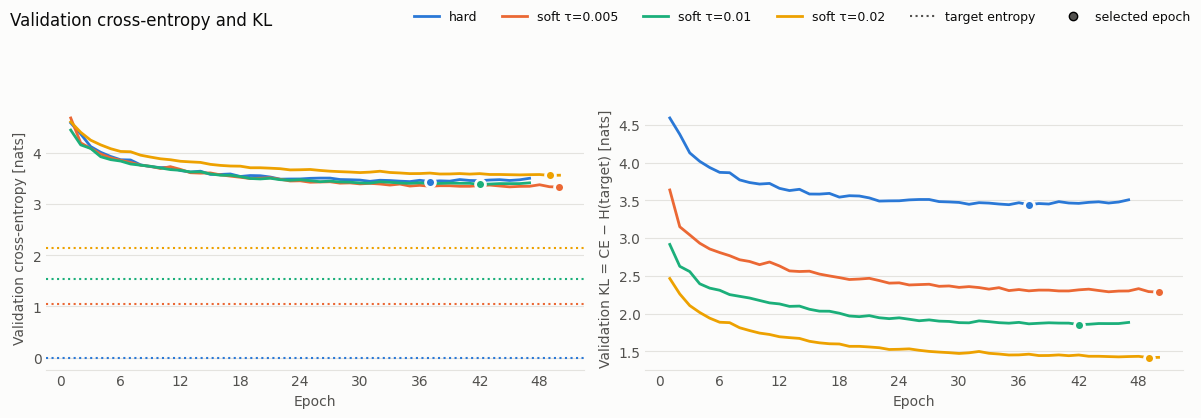

In [3]:
fig, (ax_ce, ax_kl) = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=SURFACE)
for label, h in histories.items():
    color, b = DATASET_COLORS[label], best[label]
    ax_ce.plot(h["epoch"], h["val_loss"], color=color, linewidth=2)
    ax_ce.axhline(h["val_entropy"].iloc[0], color=color, linewidth=1.5, linestyle=":")
    ax_ce.scatter([b["epoch"]], [b["val_loss"]], s=50, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
    ax_kl.plot(h["epoch"], h["val_kl"], color=color, linewidth=2)
    ax_kl.scatter([b["epoch"]], [b["val_kl"]], s=50, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
for ax, ylabel in ((ax_ce, "Validation cross-entropy [nats]"), (ax_kl, "Validation KL = CE − H(target) [nats]")):
    ax.set_xlabel("Epoch", color=INK_MUTED)
    ax.set_ylabel(ylabel, color=INK_MUTED)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    style(ax)
handles = dataset_handles(Line2D([0], [0], color=INK_MUTED, linewidth=1.5, linestyle=":", label="target entropy"),
                          BEST_HANDLE)
finish(fig, "Validation cross-entropy and KL", handles, "ce_kl")

## Train vs. validation cross-entropy

One panel per dataset. A validation CE that turns up while the train CE keeps falling is overfitting.
The train CE is the running mean over each epoch while the weights still change (and with dropout
active), so it lags behind and sits slightly high, most visibly in the first epochs. The dashed line is
the validation target entropy; the train targets have about the same.

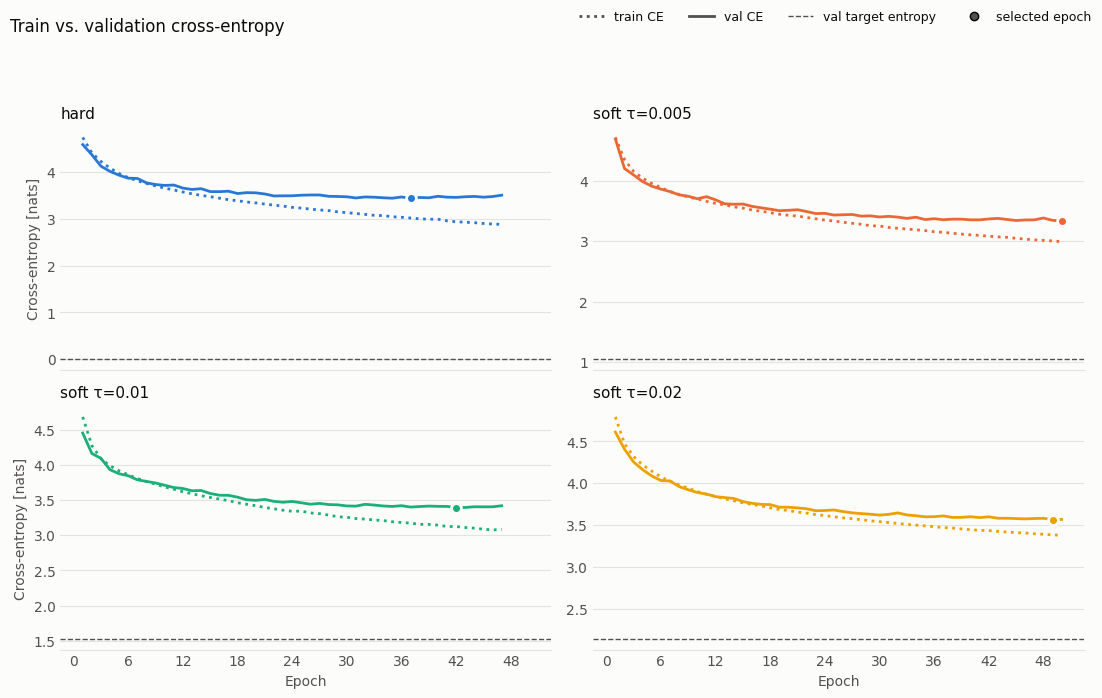

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), facecolor=SURFACE, sharex=True)
for ax, (label, h) in zip(axes.flat, histories.items()):
    color, b = DATASET_COLORS[label], best[label]
    ax.plot(h["epoch"], h["train_loss"], color=color, linewidth=2, linestyle=":")
    ax.plot(h["epoch"], h["val_loss"], color=color, linewidth=2)
    ax.axhline(h["val_entropy"].iloc[0], color=INK_MUTED, linewidth=1, linestyle="--")
    ax.scatter([b["epoch"]], [b["val_loss"]], s=50, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.set_title(label, loc="left", color=INK, fontsize=11)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    style(ax)
for ax in axes[1]:
    ax.set_xlabel("Epoch", color=INK_MUTED)
for ax in axes[:, 0]:
    ax.set_ylabel("Cross-entropy [nats]", color=INK_MUTED)
handles = [Line2D([0], [0], color=INK_MUTED, linewidth=2, linestyle=":", label="train CE"),
           Line2D([0], [0], color=INK_MUTED, linewidth=2, label="val CE"),
           Line2D([0], [0], color=INK_MUTED, linewidth=1, linestyle="--", label="val target entropy"),
           BEST_HANDLE]
finish(fig, "Train vs. validation cross-entropy", handles, "train_vs_val_ce")

## Top-k accuracy

Share of validation states where the Tutor's action is the argmax (top-1) or among the 5 / 20 highest
logits. For soft labels the Tutor's action is the argmax of the target, so all datasets are scored
against the same action.

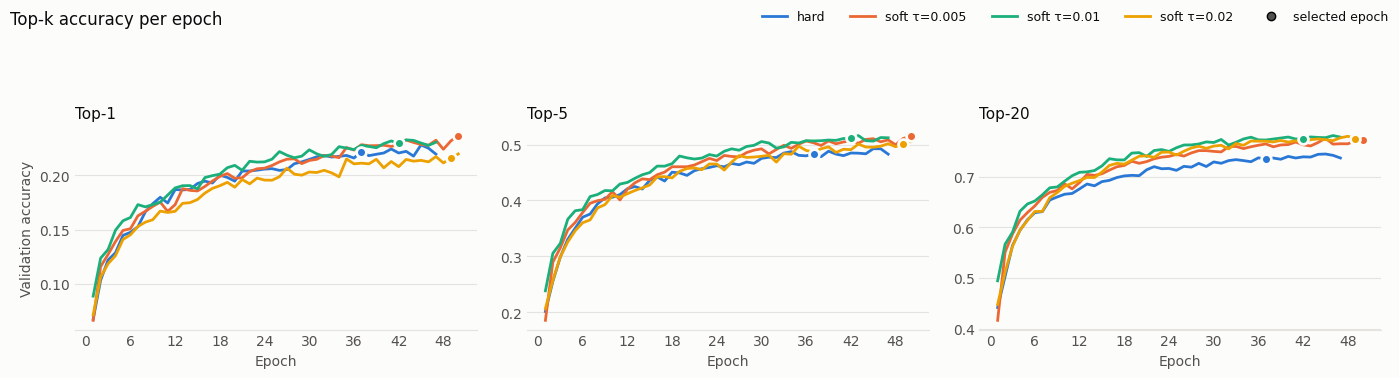

In [5]:
TOPK_COLUMNS = {"val_accuracy": "Top-1", "val_top5": "Top-5", "val_top20": "Top-20"}
fig, axes = plt.subplots(1, len(TOPK_COLUMNS), figsize=(14, 3.8), facecolor=SURFACE, sharex=True)
for ax, (column, title) in zip(axes, TOPK_COLUMNS.items()):
    for label, h in histories.items():
        if column not in h:  # runs from before top-20 was logged
            continue
        color, b = DATASET_COLORS[label], best[label]
        ax.plot(h["epoch"], h[column], color=color, linewidth=2)
        ax.scatter([b["epoch"]], [b[column]], s=50, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Epoch", color=INK_MUTED)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    style(ax)
axes[0].set_ylabel("Validation accuracy", color=INK_MUTED)
finish(fig, "Top-k accuracy per epoch", dataset_handles(BEST_HANDLE), "topk_per_epoch")

## Regret per epoch

Left: mean regret of the argmax, its simulated max rho minus that of the best valid action, over states
where the argmax is valid. The best valid action is the Tutor's action except on near-ties, where the
Tutor prefers do-nothing (within its margin); section B measures regret against the Tutor's action
itself. Right: share of states whose argmax is invalid (illegal or ending the episode in simulation).
These are left out of the regret, so a model drifting towards invalid actions would look better on the
left alone. Runs that log it (`junior2`) get a third panel: the regret of top-20 simulation, the
`junior2` objective (see "Study objective").

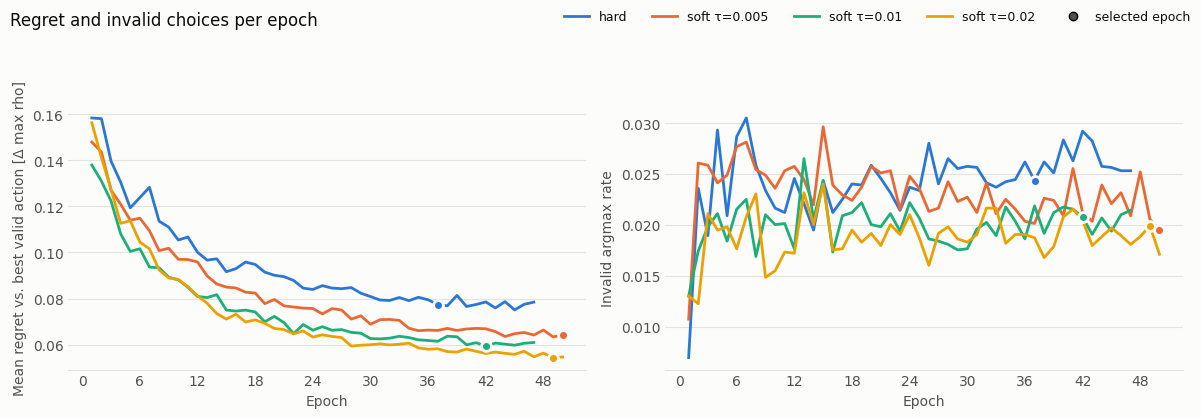

In [6]:
panels = [("val_regret", "Mean regret vs. best valid action [Δ max rho]"), ("val_invalid_rate", "Invalid argmax rate")]
if all("val_regret_top20" in h for h in histories.values()):
    panels.append(("val_regret_top20", "Regret of top-20 simulation [Δ max rho]"))

fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4.2), facecolor=SURFACE)
for ax, (column, ylabel) in zip(axes, panels):
    for label, h in histories.items():
        color, b = DATASET_COLORS[label], best[label]
        ax.plot(h["epoch"], h[column], color=color, linewidth=2)
        ax.scatter([b["epoch"]], [b[column]], s=50, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.set_ylabel(ylabel, color=INK_MUTED)
    ax.set_xlabel("Epoch", color=INK_MUTED)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    style(ax)
finish(fig, "Regret and invalid choices per epoch", dataset_handles(BEST_HANDLE), "regret_per_epoch")

# B. Selected model (validation, per state)

## Top-k curve

Left: share of states where the Tutor's action is among the k highest logits, for every k. Right: share
of states where at least one of the k highest logits is a *good* action (simulated max rho within the
good-action tolerance of the best valid action), over states with a valid action. The right panel is
what top-k simulation needs: a good action somewhere in the shortlist, not necessarily the Tutor's.
Vertical lines: the k of the top-k rollouts.

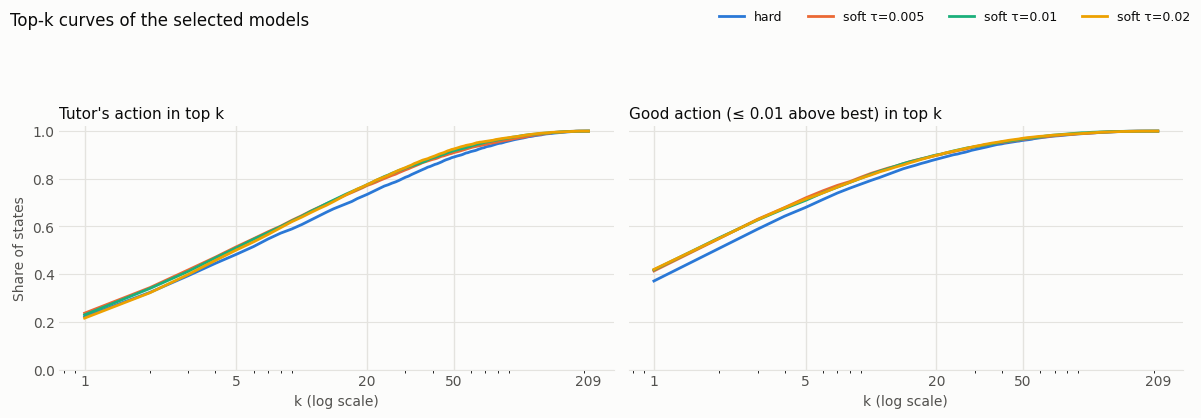

Tutor's action                      good action                \
                         1      5      20     50          1      5      20   
hard                  0.222  0.483  0.735  0.891       0.371  0.680  0.882   
soft τ=0.005          0.237  0.515  0.772  0.910       0.414  0.720  0.898   
soft τ=0.01           0.229  0.511  0.775  0.918       0.418  0.710  0.900   
soft τ=0.02           0.216  0.502  0.775  0.925       0.420  0.715  0.899   

                     
                 50  
hard          0.961  
soft τ=0.005  0.965  
soft τ=0.01   0.968  
soft τ=0.02   0.970

In [7]:
ks = np.arange(1, N_ACTIONS + 1)


def share_at_most(ranks: np.ndarray, k: np.ndarray) -> np.ndarray:
    """Share of `ranks` that are <= each k."""
    return np.searchsorted(np.sort(ranks), k, side="right") / len(ranks)


topk_curves = {label: share_at_most(df["tutor_rank"].to_numpy(), ks) for label, df in states.items()}
good_curves = {label: share_at_most(df.loc[np.isfinite(df["rho_best"]), "good_rank"].to_numpy(), ks)
               for label, df in states.items()}

fig, (ax_tutor, ax_good) = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=SURFACE, sharey=True)
for ax, curves in ((ax_tutor, topk_curves), (ax_good, good_curves)):
    for k in K_MARKS:
        ax.axvline(k, color=GRID, linewidth=1, zorder=0)
    for label, curve in curves.items():
        ax.plot(ks, curve, color=DATASET_COLORS[label], linewidth=2)
    ax.set_xscale("log")
    ax.set_xticks(K_MARKS + (N_ACTIONS,), [str(k) for k in K_MARKS + (N_ACTIONS,)])
    ax.set_xlabel("k (log scale)", color=INK_MUTED)
    ax.set_ylim(0, 1.02)
    style(ax)
ax_tutor.set_ylabel("Share of states", color=INK_MUTED)
ax_tutor.set_title("Tutor's action in top k", loc="left", color=INK, fontsize=11)
ax_good.set_title(f"Good action (≤ {TOLERANCE:g} above best) in top k", loc="left", color=INK, fontsize=11)
finish(fig, "Top-k curves of the selected models", dataset_handles(), "topk_curve")

idx = np.array(K_MARKS) - 1
pd.concat({"Tutor's action": pd.DataFrame({label: c[idx] for label, c in topk_curves.items()}, index=K_MARKS).T,
           "good action": pd.DataFrame({label: c[idx] for label, c in good_curves.items()}, index=K_MARKS).T},
          axis=1).round(3)

## Regret against the Tutor's action

Regret = simulated max rho of the argmax minus that of the Tutor's action, over states where the
Tutor's action is valid. Left: distribution of the regret where the argmax is a valid action other than
the Tutor's (the size of the misses). It can be negative where the model picks a topology action that
the Tutor turned down for do-nothing on a near-tie. Right: all states split into exact match, a
different action within the tolerance, a worse one, and an invalid one. Together they show whether the
mean regret comes from many small misses or few large ones.

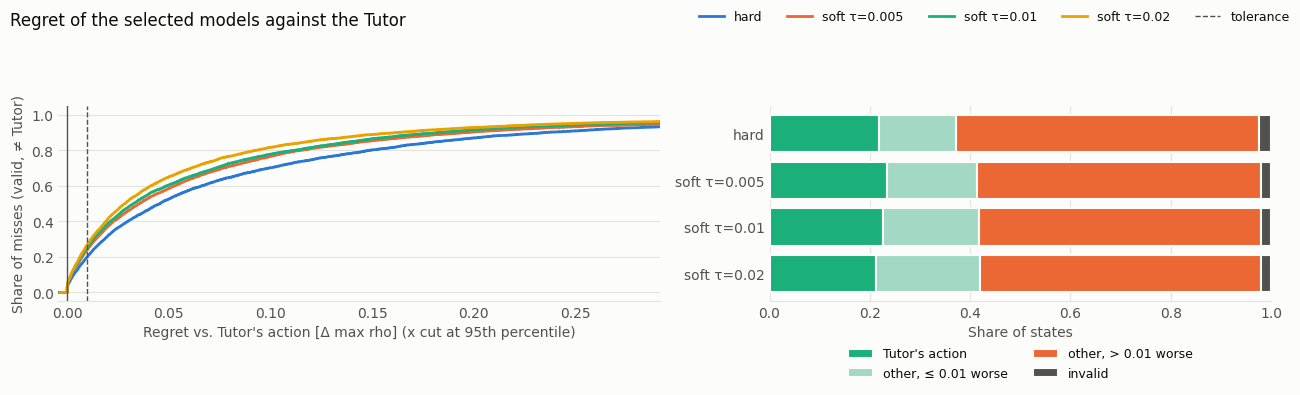

,Tutor's action,"other, ≤ 0.01 worse","other, > 0.01 worse",invalid
hard,0.218,0.153,0.604,0.025
soft τ=0.005,0.233,0.180,0.567,0.020
soft τ=0.01,0.226,0.192,0.561,0.021
soft τ=0.02,0.212,0.208,0.560,0.020


In [8]:
def miss_regret(df: pd.DataFrame) -> np.ndarray:
    return np.sort(df.loc[df["tutor_valid"] & df["pred_valid"] & ~df["match"], "regret"].to_numpy())


def outcome_shares(df: pd.DataFrame) -> pd.Series:
    df = df[df["tutor_valid"]]
    other = df["pred_valid"] & ~df["match"]
    return pd.Series({
        "Tutor's action": df["match"].mean(),
        f"other, ≤ {TOLERANCE:g} worse": (other & (df["regret"] <= TOLERANCE)).mean(),
        f"other, > {TOLERANCE:g} worse": (other & (df["regret"] > TOLERANCE)).mean(),
        "invalid": (~df["pred_valid"]).mean(),
    })


misses = {label: miss_regret(df) for label, df in states.items()}
outcomes = pd.DataFrame({label: outcome_shares(df) for label, df in states.items()}).T
OUTCOME_COLORS = ["#1baf7a", "#a3d9c4", "#eb6834", "#52514e"]

fig, (ax_ecdf, ax_bar) = plt.subplots(1, 2, figsize=(13, 4.2), facecolor=SURFACE, width_ratios=(1.2, 1))
for label, r in misses.items():
    ax_ecdf.step(r, np.arange(1, len(r) + 1) / len(r), where="post", color=DATASET_COLORS[label], linewidth=2)
ax_ecdf.axvline(0, color=INK_MUTED, linewidth=1)
ax_ecdf.axvline(TOLERANCE, color=INK_MUTED, linewidth=1, linestyle="--")
upper = np.quantile(np.concatenate(list(misses.values())), 0.95)
ax_ecdf.set_xlim(min(r.min() for r in misses.values()), upper)
ax_ecdf.set_xlabel("Regret vs. Tutor's action [Δ max rho] (x cut at 95th percentile)", color=INK_MUTED)
ax_ecdf.set_ylabel("Share of misses (valid, ≠ Tutor)", color=INK_MUTED)
style(ax_ecdf)

y = np.arange(len(outcomes))[::-1]
left = np.zeros(len(outcomes))
for column, color in zip(outcomes.columns, OUTCOME_COLORS):
    ax_bar.barh(y, outcomes[column], left=left, color=color, edgecolor=SURFACE, linewidth=1.5, label=column)
    left += outcomes[column].to_numpy()
ax_bar.set_yticks(y, outcomes.index, color=INK)
ax_bar.set_xlim(0, 1)
ax_bar.set_xlabel("Share of states", color=INK_MUTED)
ax_bar.legend(frameon=False, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=9, labelcolor=INK)
style(ax_bar)
ax_bar.yaxis.grid(False)
ax_bar.xaxis.grid(True, color=GRID, linewidth=0.8)
handles = dataset_handles(Line2D([0], [0], color=INK_MUTED, linewidth=1, linestyle="--", label="tolerance"))
finish(fig, "Regret of the selected models against the Tutor", handles, "regret_distribution")
outcomes.round(3)

## Confidence

Left: distribution of the probability the policy gives the Tutor's action (log scale, the lowest 0.5 %
folded into the first bin; the dotted line is the uniform policy, 1/n_actions). Soft-label models are trained to spread mass over near-equivalent
actions, so they should give the Tutor's action less but its runners-up more. Right: reliability
diagram, the top-1 accuracy of states binned by the probability of the argmax. On the diagonal the
probabilities are calibrated; below it the model is overconfident. ECE: expected calibration error,
the state-weighted mean gap. Relevant when the policy's probabilities drive sampling or action masks
in RL.

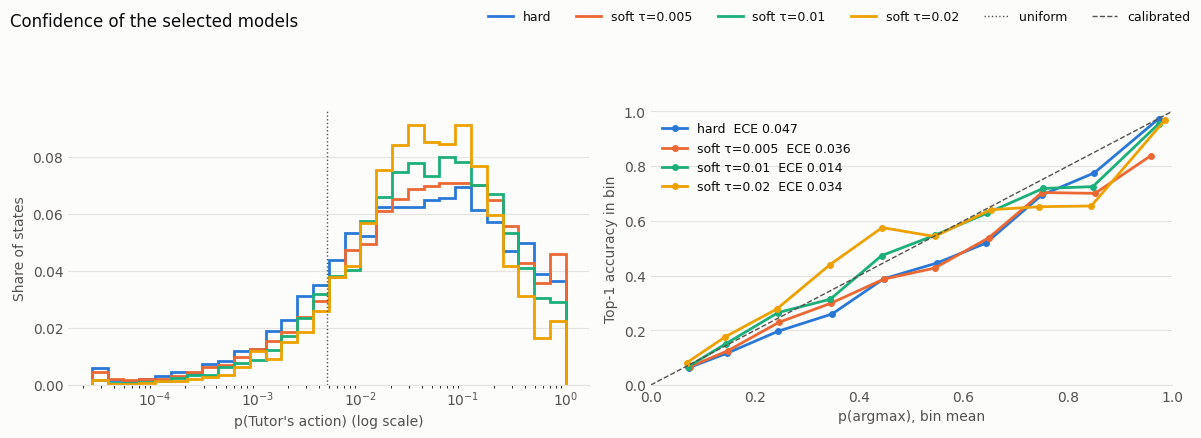

In [9]:
CONF_BINS = np.linspace(0, 1, 11)


def reliability(df: pd.DataFrame) -> tuple[pd.DataFrame, float]:
    """Mean confidence and accuracy per bin of p(argmax), and the expected calibration error."""
    bins = pd.cut(df["p_pred"], CONF_BINS, include_lowest=True)
    table = df.groupby(bins, observed=True).agg(confidence=("p_pred", "mean"), accuracy=("match", "mean"),
                                                 n=("match", "size"))
    ece = float((table["n"] * (table["confidence"] - table["accuracy"]).abs()).sum() / len(df))
    return table, ece


calibration = {label: reliability(df) for label, df in states.items()}
# Bins from the 0.5th percentile up; the few states below land in the first bin.
p_low = min(np.quantile(df["p_tutor"], 0.005) for df in states.values())
p_bins = np.logspace(np.log10(p_low), 0, 31)

fig, (ax_hist, ax_rel) = plt.subplots(1, 2, figsize=(12, 4.4), facecolor=SURFACE)
for label, df in states.items():
    color = DATASET_COLORS[label]
    ax_hist.hist(df["p_tutor"].clip(lower=p_low), bins=p_bins, weights=np.full(len(df), 1 / len(df)), histtype="step",
                 color=color, linewidth=2)
    table, ece = calibration[label]
    table = table[table["n"] >= 20]  # too few states for a stable accuracy
    ax_rel.plot(table["confidence"], table["accuracy"], color=color, linewidth=2, marker="o", markersize=4,
                label=f"{label}  ECE {ece:.3f}")
ax_hist.axvline(1 / N_ACTIONS, color=INK_MUTED, linewidth=1, linestyle=":")
ax_hist.set_xscale("log")
ax_hist.set_xlabel("p(Tutor's action) (log scale)", color=INK_MUTED)
ax_hist.set_ylabel("Share of states", color=INK_MUTED)
ax_rel.plot([0, 1], [0, 1], color=INK_MUTED, linewidth=1, linestyle="--")
ax_rel.set_xlim(0, 1)
ax_rel.set_ylim(0, 1)
ax_rel.set_xlabel("p(argmax), bin mean", color=INK_MUTED)
ax_rel.set_ylabel("Top-1 accuracy in bin", color=INK_MUTED)
ax_rel.legend(frameon=False, fontsize=9, labelcolor=INK, loc="upper left")
for ax in (ax_hist, ax_rel):
    style(ax)
handles = dataset_handles(Line2D([0], [0], color=INK_MUTED, linewidth=1, linestyle=":", label="uniform"),
                          Line2D([0], [0], color=INK_MUTED, linewidth=1, linestyle="--", label="calibrated"))
finish(fig, "Confidence of the selected models", handles, "confidence")

## Summary

Selected model per dataset on the validation split. KL and (if logged) the regret of top-20
simulation are those of the selected epoch. Regret is against the Tutor's action, over states
where both actions are valid; good action rate: argmax within the tolerance of the best valid action.

In [10]:
def summary_row(label: str) -> dict[str, float]:
    df = states[label]
    both_valid = df["tutor_valid"] & df["pred_valid"]
    return {
        "selected epoch": int(best[label]["epoch"]),
        **{name: best[label][column] for column, name in (("val_kl", "KL"), ("val_regret_top20", "regret top-20"))
           if column in best[label]},
        **{f"top-{k}": (df["tutor_rank"] <= k).mean() for k in (1, 5, 20)},
        "good action rate": (df.loc[np.isfinite(df["rho_best"]), "good_rank"] == 1).mean(),
        "regret vs. Tutor": df.loc[both_valid, "regret"].mean(),
        "invalid rate": (~df["pred_valid"]).mean(),
        "mean p(Tutor)": df["p_tutor"].mean(),
        "ECE": calibration[label][1],
    }


pd.DataFrame({label: summary_row(label) for label in RUNS}).T.round(4)

,selected epoch,KL,top-1,top-5,top-20,good action rate,regret vs. Tutor,invalid rate,mean p(Tutor),ECE
hard,37.0,3.4426,0.2217,0.4834,0.7347,0.3714,0.0773,0.0300,0.1302,0.0469
soft τ=0.005,50.0,2.2858,0.2366,0.5150,0.7721,0.4136,0.0640,0.0251,0.1401,0.0357
soft τ=0.01,42.0,1.8568,0.2295,0.5109,0.7755,0.4181,0.0592,0.0264,0.1234,0.0141
soft τ=0.02,49.0,1.4190,0.2158,0.5016,0.7754,0.4200,0.0543,0.0256,0.1050,0.0341


# C. Survival on the validation env

Rollouts of the selected models on all 144 chronics of the Grid2Op env `l2rpn_wcci_2020_val`
(`experiments/imitation_rollout.py`), for every study set at once (independent of `STUDY_PREFIX`):

- **junior**: best trials of the first Junior experiment.
- **junior, complete obs**: the same best configurations retrained once with CompleteGraphObsSpace,
  everything else unchanged (`OUT_SUFFIX=_complete_obs slurm/unicluster/junior_retrain.sh`). Against
  *junior* this isolates the observation space, against *junior2* the HPO changes.
- **junior2**: best trials of Junior Continued.
- **junior2 MLP**: best trial of the Fraunhofer-style MLP study (hard labels).

Sets without any run are left out. Every policy plays the same chronics with the same seeds. While max
rho stays at or below 0.95 every agent plays do-nothing, and disconnected lines are reconnected by a
fixed rule. Above 0.95 the agent decides:

- **argmax**: the network's most probable action.
- **top-k**: the network's k most probable actions and do-nothing are simulated, and the Tutor's rule
  picks among them (the best one, if it beats do-nothing by more than the Tutor's margin).
- **Tutor** (all actions): top-k with every action, i.e. the Tutor itself.
- **Do-nothing**: always do-nothing.

Metrics per policy and mode:

- **full survival %**: share of chronics survived to the end, with its standard error
  $\sqrt{p(1-p)/n}$ ($n$ = 144 chronics gives about ±3–4 points, so smaller differences are noise).
- **mean survival %**: mean over chronics of steps survived / chronic length.
- **decisions / day**: steps at which the agent was asked to decide (max rho above 0.95).
- **actions / day**: decisions in which the agent's own topology action was executed; do-nothing
  decisions and the heuristic line reconnections don't count.
- **illegal / day**: decisions in which the agent chose a topology action that the env rejected as
  illegal (grid2op then plays do-nothing). Only argmax can do this: top-k simulation filters illegal
  actions out.

All per-day rates are per day survived (288 steps), as the ratio of the sums over all chronics; the mean
of per-chronic rates would be dominated by chronics that end after a few hours. Missing rollout folders
show as –, and so do actions and illegal actions for rollouts made before these were logged (rerun them).

In [11]:
SURVIVAL_COLUMNS = ["chronics", "full survival %", "± SE", "mean survival %",
                    "decisions / day", "actions / day", "illegal / day"]


def rollout_dirs() -> dict[tuple[str, str, str], Path]:
    """(set, policy, mode) -> folder of episodes_valenv_*.csv, for every row of the survival table."""
    dirs = {}
    for set_name, runs in SURVIVAL_SETS.items():
        if not any(run.exists() for run in runs.values()):
            continue  # set not run (or not copied) yet
        for label, run in runs.items():
            for mode, folder in ROLLOUT_MODES.items():
                dirs[(set_name, label, mode)] = run / folder
    dirs[("reference", "Tutor", f"all {N_ACTIONS}")] = REFERENCE_ROLLOUTS["Tutor"]
    dirs[("reference", "Do-nothing", "–")] = REFERENCE_ROLLOUTS["Do-nothing"]
    return dirs


def per_day(episodes: pd.DataFrame, column: str) -> float:
    """Sum of a count column per day survived; NaN if a rollout predates the column (stored as -1)."""
    if (episodes[column] < 0).any():
        return np.nan
    return episodes[column].sum() / (episodes["steps_survived"].sum() / STEPS_PER_DAY)


def survival_row(episodes: pd.DataFrame) -> list[float]:
    """Values of SURVIVAL_COLUMNS for the episodes of one policy and mode."""
    full = episodes["survived"].mean()
    return [len(episodes), 100 * full, 100 * np.sqrt(full * (1 - full) / len(episodes)),
            100 * (episodes["steps_survived"] / episodes["max_step"]).mean(),
            *(per_day(episodes, column) for column in ("n_decisions", "n_actions", "n_illegal"))]


rows = {}
for key, folder in rollout_dirs().items():
    files = sorted(folder.glob("episodes_valenv_*.csv"))
    rows[key] = survival_row(load_episodes(*files)) if files else [np.nan] * len(SURVIVAL_COLUMNS)
survival = pd.DataFrame.from_dict(rows, orient="index", columns=SURVIVAL_COLUMNS)
survival.index = pd.MultiIndex.from_tuples(survival.index, names=["set", "policy", "mode"])
survival.style.format({"chronics": "{:.0f}", "decisions / day": "{:.2f}", "actions / day": "{:.2f}",
                       "illegal / day": "{:.2f}"}, precision=1, na_rep="–")

# D. Hyperparameter search

One Optuna study per dataset (`experiments/pretrain_hpo.py`, search space in
`configs/rllib/pretrain_hpo.yaml`) minimises the study objective (see "Study objective"). Trials per state: complete trials were
trained until early stopping, pruned ones were stopped by the pruner after a poor epoch.

In [12]:
studies = {label: open_study(path, path.name) for label, path in STUDIES.items()}
trials = pd.concat([pd.read_csv(path / TRIALS_FILE).assign(dataset=label) for label, path in STUDIES.items()],
                   ignore_index=True)
trials.groupby(["dataset", "state"], sort=False).size().unstack(fill_value=0)

state,COMPLETE,PRUNED
dataset,,
hard,13,30
soft τ=0.005,6,37
soft τ=0.01,6,37
soft τ=0.02,8,35


## Optimization history

Every trial's objective value (filled: complete, hollow: pruned at its last reported epoch) and the
best complete value so far. Validation KL values are not comparable between datasets (softer targets
are easier to fit); regret values are.

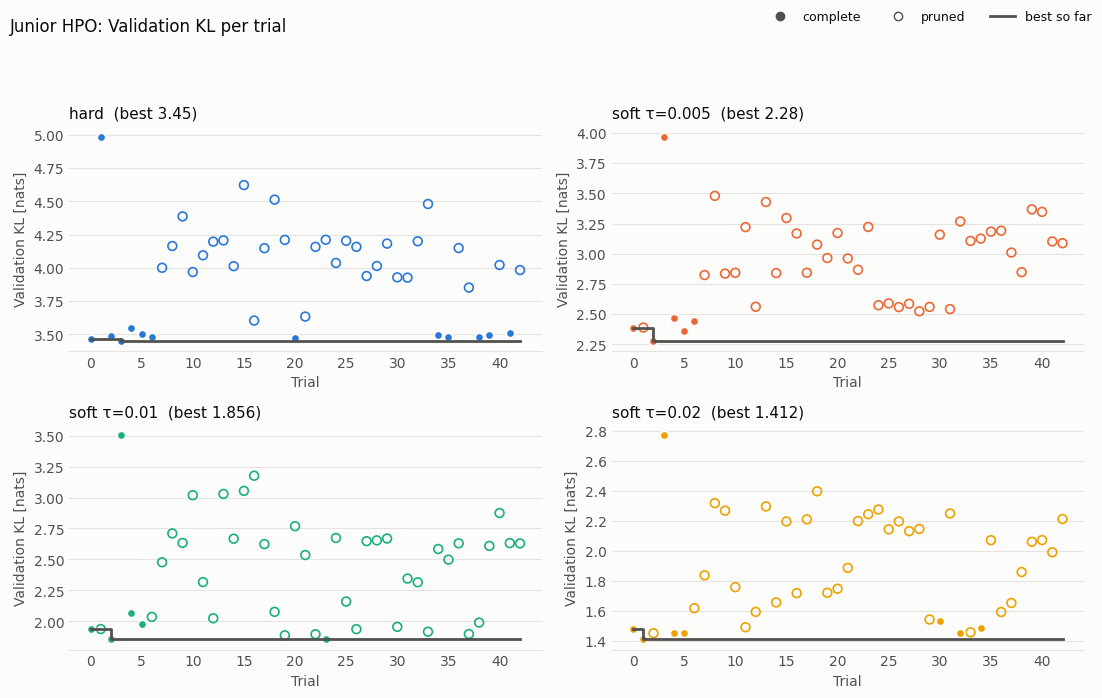

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), facecolor=SURFACE)
for ax, (label, group) in zip(axes.flat, trials.groupby("dataset", sort=False)):
    color = DATASET_COLORS[label]
    group = group.sort_values("number")
    done, pruned = group[group["state"] == "COMPLETE"], group[group["state"] == "PRUNED"]
    ax.scatter(pruned["number"], pruned["value"], s=40, facecolors="none", edgecolors=color, linewidths=1.2)
    ax.scatter(done["number"], done["value"], s=40, color=color, edgecolors=SURFACE, linewidths=1.5)
    best_so_far = done.set_index("number")["value"].cummin().reindex(group["number"]).ffill()
    ax.plot(best_so_far.index, best_so_far.values, color=INK_MUTED, linewidth=2, drawstyle="steps-post")
    ax.set_title(f"{label}  (best {done['value'].min():.4g})", loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Trial", color=INK_MUTED)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel(f"{OBJECTIVE_NAME} [{OBJECTIVE_UNIT}]", color=INK_MUTED)
    style(ax)
handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=INK_MUTED, markeredgecolor=INK_MUTED, label="complete"),
           Line2D([0], [0], marker="o", color="none", markerfacecolor="none", markeredgecolor=INK_MUTED, label="pruned"),
           Line2D([0], [0], color=INK_MUTED, linewidth=2, label="best so far")]
finish(fig, f"Junior HPO: {OBJECTIVE_NAME} per trial", handles, "optimization_history")

## Hyperparameter importance

fANOVA importance (`optuna.importance.get_param_importances`) of each hyperparameter for the
study objective, per study and over complete trials. Importances sum to 1 within a study.

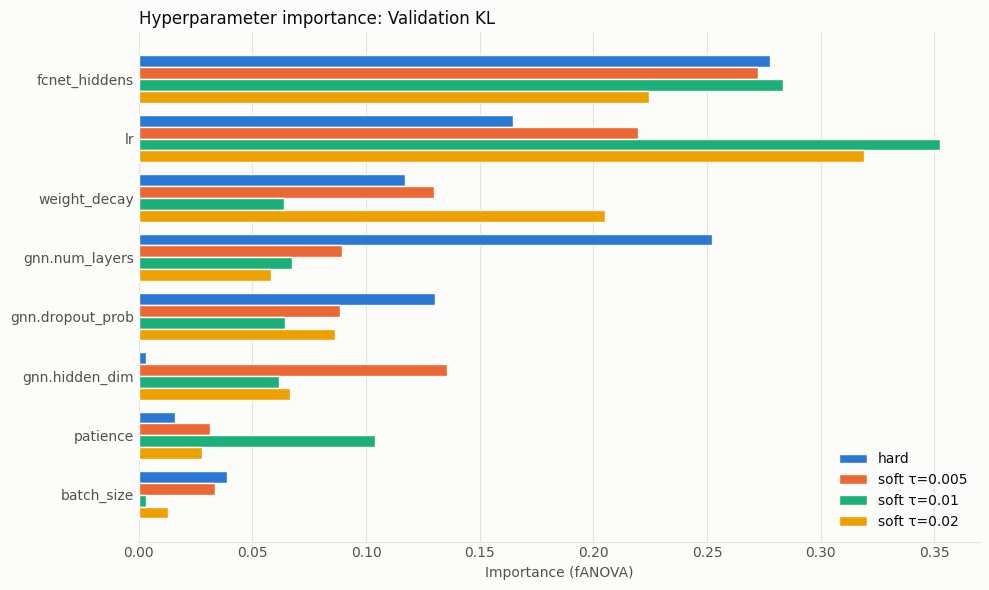

In [14]:
importance = pd.DataFrame({label: optuna.importance.get_param_importances(study)
                           for label, study in studies.items()}).fillna(0.0)
importance.index = [name.split(".", 1)[-1] for name in importance.index]
importance = importance.loc[importance.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 6), facecolor=SURFACE)
height = 0.8 / len(STUDIES)
y = np.arange(len(importance))
for i, label in enumerate(STUDIES):
    ax.barh(y - (i - (len(STUDIES) - 1) / 2) * height, importance[label], height,
            color=DATASET_COLORS[label], edgecolor=SURFACE, linewidth=1, label=label)
ax.set_yticks(y, importance.index)
ax.set_xlabel("Importance (fANOVA)", color=INK_MUTED)
ax.set_title(f"Hyperparameter importance: {OBJECTIVE_NAME}", loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, labelcolor=INK, loc="lower right")
style(ax)
ax.yaxis.grid(False)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
fig.tight_layout()
save(fig, "param_importance")
plt.show()

## Best trial per dataset

Hyperparameters of the best complete trial of each study (lowest objective value), one column per
dataset. `search space`: the values the study sampled from (`{…}` categorical, `[low, high]`
uniform or log-uniform). `mean importance`: fANOVA importance averaged over the four studies;
hyperparameters are sorted by it.

In [15]:
def format_space(spec: dict) -> str:
    """Search space of one hyperparameter as written in the HPO config."""
    if spec["type"] == "categorical":
        return "{" + ", ".join(str(choice) for choice in spec["choices"]) + "}"
    return f"[{spec['low']:g}, {spec['high']:g}]" + (" (log)" if spec.get("log") else "")


def format_value(value) -> str:
    return f"{value:.3g}" if isinstance(value, float) else str(value)


search_space = STUDY_CONFIG["hpo"]["search_space"]
best_rows = (trials[trials["state"] == "COMPLETE"].sort_values("value")
             .groupby("dataset", sort=False).head(1).set_index("dataset").loc[list(STUDIES)])

trial_info = best_rows[["number", "user_attrs_best_epoch", "user_attrs_n_epochs"]].astype(int).set_axis(
    ["trial", "best epoch", "epochs run"], axis=1).T
hyperparams = best_rows[[f"params_{name}" for name in search_space]].set_axis(
    [name.split(".", 1)[-1] for name in search_space], axis=1).T.map(format_value)
hyperparams["search space"] = [format_space(spec) for spec in search_space.values()]
hyperparams["mean importance"] = importance.mean(axis=1).round(3)
hyperparams = hyperparams.sort_values("mean importance", ascending=False)

pd.concat([trial_info, hyperparams]).fillna("").rename_axis(columns=None)

,hard,soft τ=0.005,soft τ=0.01,soft τ=0.02,search space,mean importance
trial,3,2,23,1,,
best epoch,39,45,43,45,,
epochs run,49,50,48,50,,
lr,0.000745,0.000745,0.00064,0.000745,"[0.0001, 0.01] (log)",0.264
fcnet_hiddens,"[128, 128]","[128, 128]","[128, 128]","[128, 128]","{[128, 128], [256, 256], [512, 512], [1024, 10...",0.264
weight_decay,0.000182,0.000182,1.17e-05,0.000182,"[1e-05, 0.01] (log)",0.129
gnn.num_layers,3,3,3,3,"{2, 3, 4}",0.117
gnn.dropout_prob,0.236,0.236,0.0613,0.236,"[0, 0.3]",0.092
gnn.hidden_dim,512,512,512,512,"{128, 256, 512, 1024}",0.067
patience,10,10,5,10,"{3, 5, 10}",0.045
